# Phase 2 exploratory analysis

This notebook describes the six stocks and the S&P 500 over 2018-2025 using only `data/processed/master_historical.csv`. The unseen master is never opened. The methods were adopted before any of these numbers were calculated; they are listed in [methodology](../docs/methodology.md#phase-2-exploratory-analysis), and the work order is in the [Phase 2 plan](../docs/phase_planning/phase_2_plan.md). The written findings are in the [Phase 2 analysis](../docs/phase_planning/phase_2_analysis.md).

All calculations live in `market_analytics.analysis`. The notebook runs them once, then reads back the saved tables and figures, so what is shown here is exactly what was exported. Nothing in this phase is fitted for later use: the betas and VIX boundaries are descriptions of 2018-2025, not parameters for the strategy.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from market_analytics.analysis.eda import run_eda

ROOT = Path.cwd().resolve()
if not (ROOT / 'pyproject.toml').is_file():
    ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').is_file()
CONFIG = ROOT / 'configs/eda.json'
METRICS = ROOT / 'outputs/metrics/eda'
FIGURES = ROOT / 'outputs/figures/eda'
pd.set_option('display.precision', 3)

metadata = run_eda(CONFIG)
table = lambda name: pd.read_csv(METRICS / f'{name}.csv')
print('Input:', metadata['input']['file'], metadata['input']['sha256'][:12], '...')
print('Coverage:', metadata['input']['first_date'], 'to', metadata['input']['last_date'],
      f"({metadata['input']['rows']} sessions, {metadata['input']['return_dates']} return dates)")
display(pd.DataFrame(metadata['validation'])[['check', 'count', 'details']])

Input: data/processed/master_historical.csv 99fdcd481630 ...
Coverage: 2018-01-02 to 2025-12-31 (2011 sessions, 2010 return dates)


,check,count,details
0,required_columns,15,
1,unique_increasing_dates_in_period,2011,2018-01-02 to 2025-12-31
2,positive_finite_closes_including_vix,16088,
3,missing_returns_only_on_first_date,7,2018-01-02
4,compounded_return_matches_close_ratio,63,
5,beta_and_r_squared_match_covariance_identities,54,
6,rolling_matches_direct_window_calculation,45,largest gap 5.662e-15
7,saved_vix_boundaries_reproduce_groups,2010,
8,stock_summary_rows,7,
9,stock_annual_summary_rows,56,


## Input checks

The run first confirms that the master's SHA-256 matches the Phase 1 manifest, then checks the columns, dates, prices, and missing values. Only the seven returns on 2018-01-02 may be missing; any other gap stops the run instead of being filled. All later checks in the table are recalculations: compounded returns against Close ratios, betas against covariance/variance, rolling windows against a direct calculation, and the expected row counts of every table.

In [2]:
assert metadata['input']['rows'] == 2011 and metadata['input']['return_dates'] == 2010
assert metadata['input']['last_date'] == '2025-12-31'
assert all(check['status'] == 'pass' for check in metadata['validation'])
assert not any('unseen' in name for name in metadata['outputs'])

## Return and risk

Returns are Close-based daily percentages, so dividends are excluded. Volatility is the sample standard deviation of daily returns times the square root of 252. The drawdown starts from wealth 1 on 2018-01-02, and that starting value counts toward the running peak.

In [3]:
summary = table('stock_summary').set_index('instrument')
display(summary[['n', 'mean_pct', 'std_pct', 'annualized_vol_pct', 'compounded_return_pct',
                 'max_drawdown_pct', 'drawdown_peak_date', 'drawdown_trough_date']])
annual = table('stock_annual_summary')
display(annual.pivot(index='instrument', columns='year', values='compounded_return_pct').round(1))
display(annual.pivot(index='instrument', columns='year', values='annualized_vol_pct').round(1))

,n,mean_pct,std_pct,annualized_vol_pct,compounded_return_pct,max_drawdown_pct,drawdown_peak_date,drawdown_trough_date
instrument,,,,,,,,
MSFT,2010,0.102,1.787,28.364,462.676,-37.556,2021-11-19,2022-11-03
GOOGL,2010,0.107,1.952,30.986,483.297,-44.320,2021-11-18,2022-11-03
NVDA,2010,0.232,3.231,51.291,3642.162,-66.362,2021-11-29,2022-10-14
AAPL,2010,0.110,1.940,30.794,531.278,-38.730,2018-10-03,2019-01-03
AMZN,2010,0.091,2.168,34.408,288.256,-56.145,2021-07-08,2022-12-28
META,2010,0.099,2.611,41.447,263.846,-76.736,2021-09-07,2022-11-03
GSPC,2010,0.054,1.235,19.600,153.931,-33.925,2020-02-19,2020-03-23


year,2018,2019,2020,2021,2022,2023,2024,2025
instrument,,,,,,,,
AAPL,-8.4,86.2,80.7,33.8,-26.8,48.2,30.1,8.6
AMZN,26.3,23.0,76.3,2.4,-49.6,80.9,44.4,5.2
GOOGL,-2.6,28.2,30.9,65.3,-39.1,58.3,35.5,65.3
GSPC,-7.0,28.9,16.3,26.9,-19.4,24.2,23.3,16.4
META,-27.7,56.6,33.1,23.1,-64.2,194.1,65.4,12.7
MSFT,18.2,55.3,41.0,51.2,-28.7,56.8,12.1,14.7
NVDA,-33.0,76.3,121.9,125.3,-50.3,238.9,171.2,38.9


year,2018,2019,2020,2021,2022,2023,2024,2025
instrument,,,,,,,,
AAPL,28.7,26.2,46.7,25.1,35.7,20.3,22.7,32.5
AMZN,36.1,22.9,38.5,24.1,50.1,33.0,28.1,34.4
GOOGL,28.2,23.7,38.5,24.3,38.7,30.3,28.1,32.4
GSPC,17.1,12.5,34.4,13.1,24.2,13.1,12.6,18.8
META,38.0,27.9,45.9,29.6,64.3,39.9,36.5,38.0
MSFT,28.3,19.9,43.9,21.1,35.3,25.1,19.9,24.3
NVDA,49.2,40.6,57.8,45.0,63.2,48.4,52.5,49.6


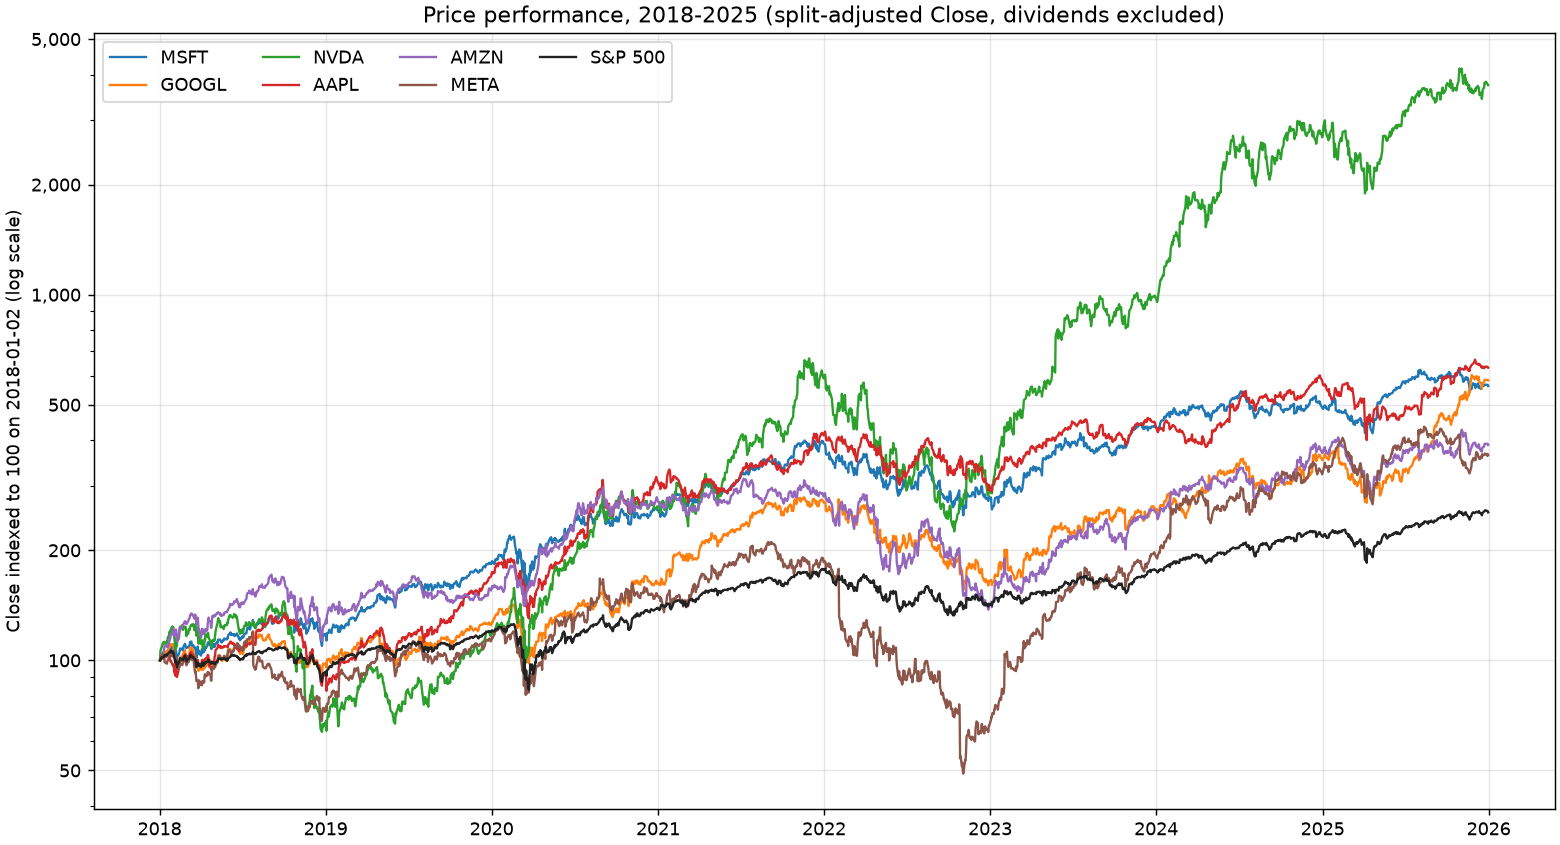

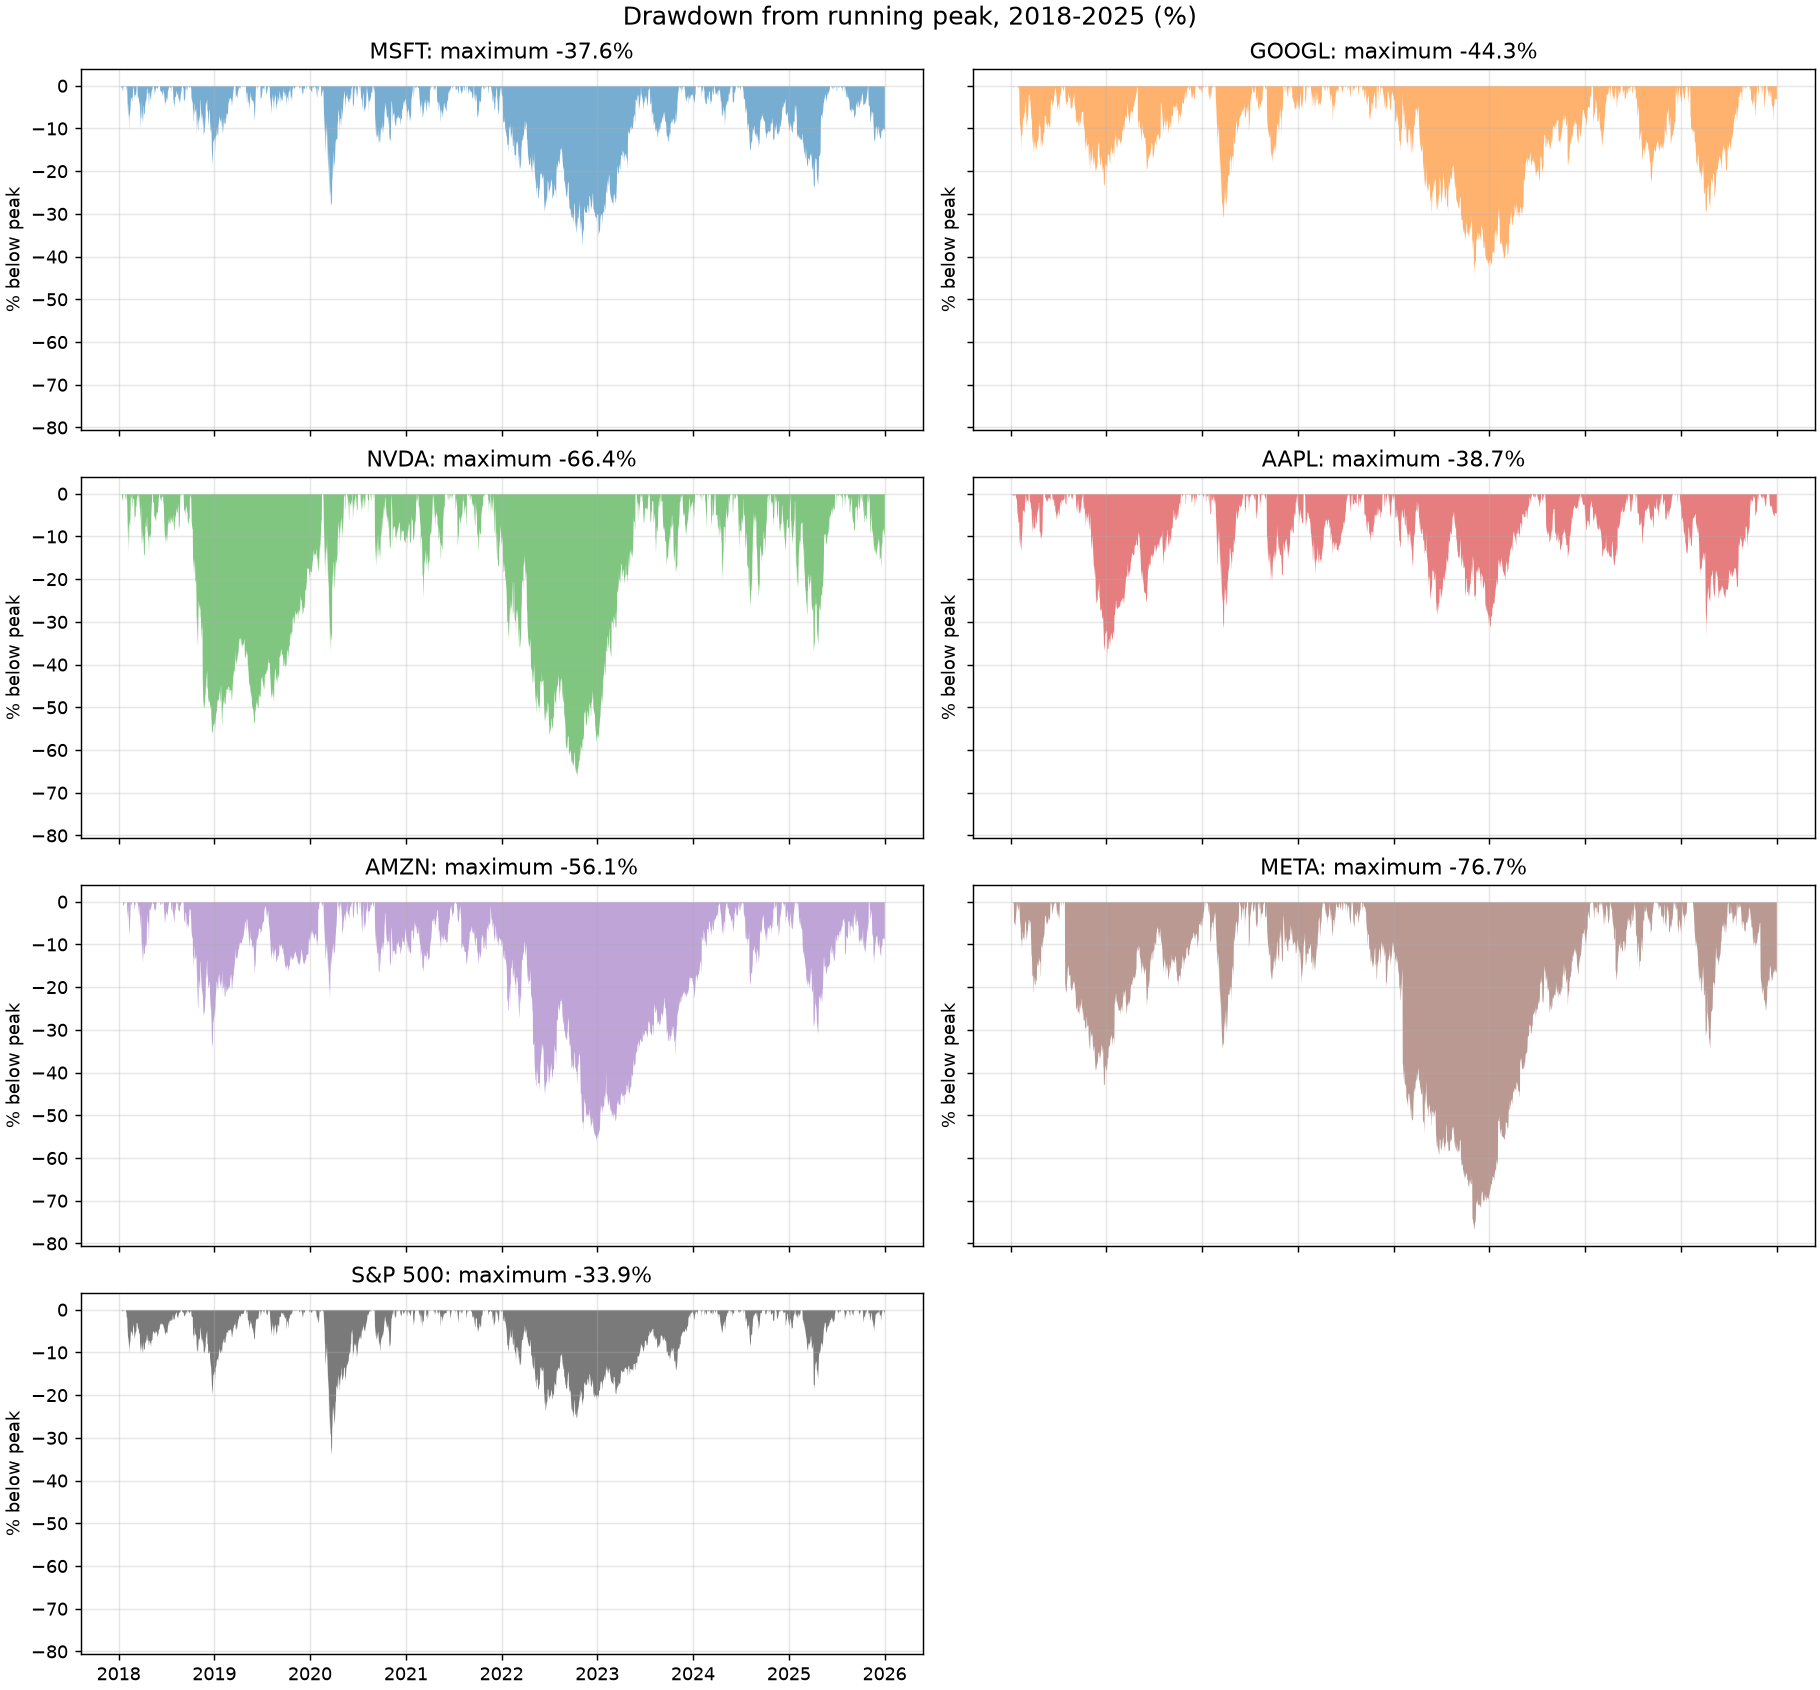

In [4]:
display(Image(FIGURES / 'performance_index.png'))
display(Image(FIGURES / 'drawdowns.png'))

NVDA's Close rose 3,642% over the eight years, far ahead of the other five (264% for META to 531% for AAPL) and the S&P 500 (154%). It also had the highest annualized volatility, 51.3%, against 28.4% for MSFT, the least volatile of the six, and 19.6% for the index. Every stock was more volatile than the S&P 500 in every year.

The deepest drawdown was META's: -76.7% from 2021-09-07 to 2022-11-03. Five of the six stocks reached their deepest point in October-December 2022. AAPL is the exception: its largest drawdown, -38.7%, ran from October 2018 to January 2019. The S&P 500's worst fall was the 2020 crash, -33.9% between 2020-02-19 and 2020-03-23. 2022 was the only year in which all seven series fell.

## All 15 pairs

Pairs are taken in the fixed display order MSFT, GOOGL, NVDA, AAPL, AMZN, META, giving MSFT_GOOGL first and AMZN_META last. The pair table reports two Pearson correlations: same-day daily returns (2,010 observations) and log Close levels (2,011 observations). Neither one is evidence of cointegration; that is tested in Phase 3, and all 15 pairs go forward to it.

,pair,return_correlation,return_n,log_price_correlation,log_price_n
0,MSFT_GOOGL,0.708,2010,0.960,2011
1,MSFT_NVDA,0.661,2010,0.938,2011
2,MSFT_AAPL,0.700,2010,0.977,2011
3,MSFT_AMZN,0.682,2010,0.884,2011
4,MSFT_META,0.609,2010,0.803,2011
5,GOOGL_NVDA,0.576,2010,0.949,2011
6,GOOGL_AAPL,0.622,2010,0.944,2011
7,GOOGL_AMZN,0.641,2010,0.886,2011
8,GOOGL_META,0.610,2010,0.837,2011
9,NVDA_AAPL,0.572,2010,0.912,2011


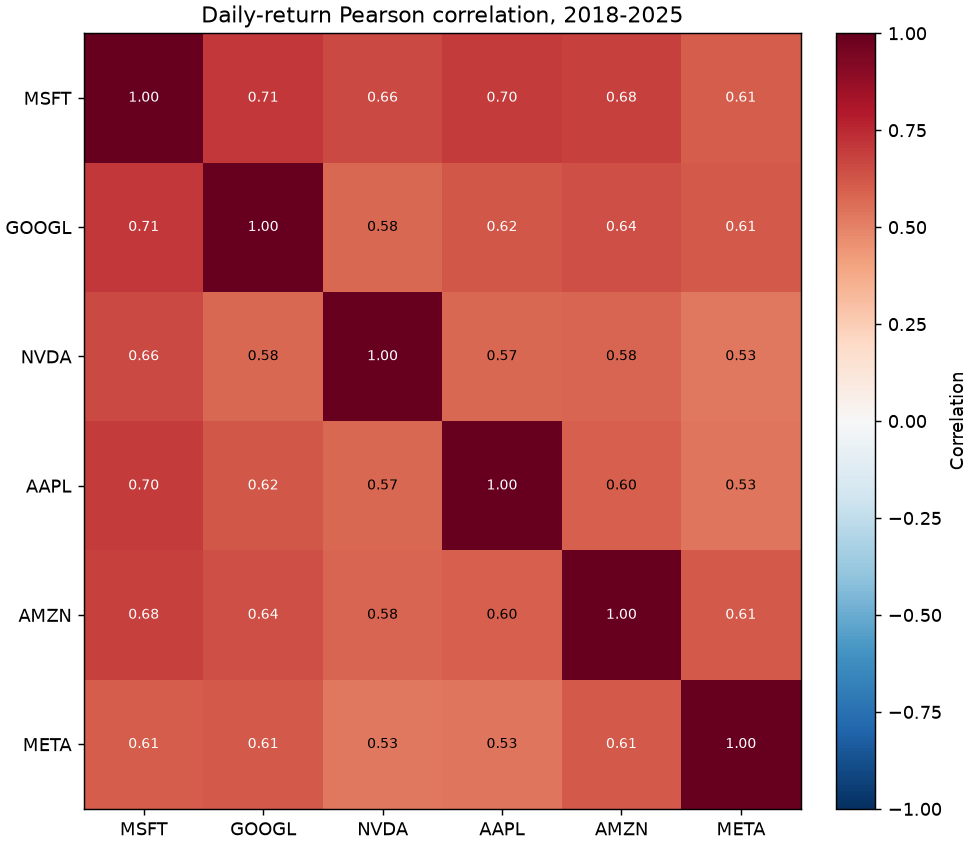

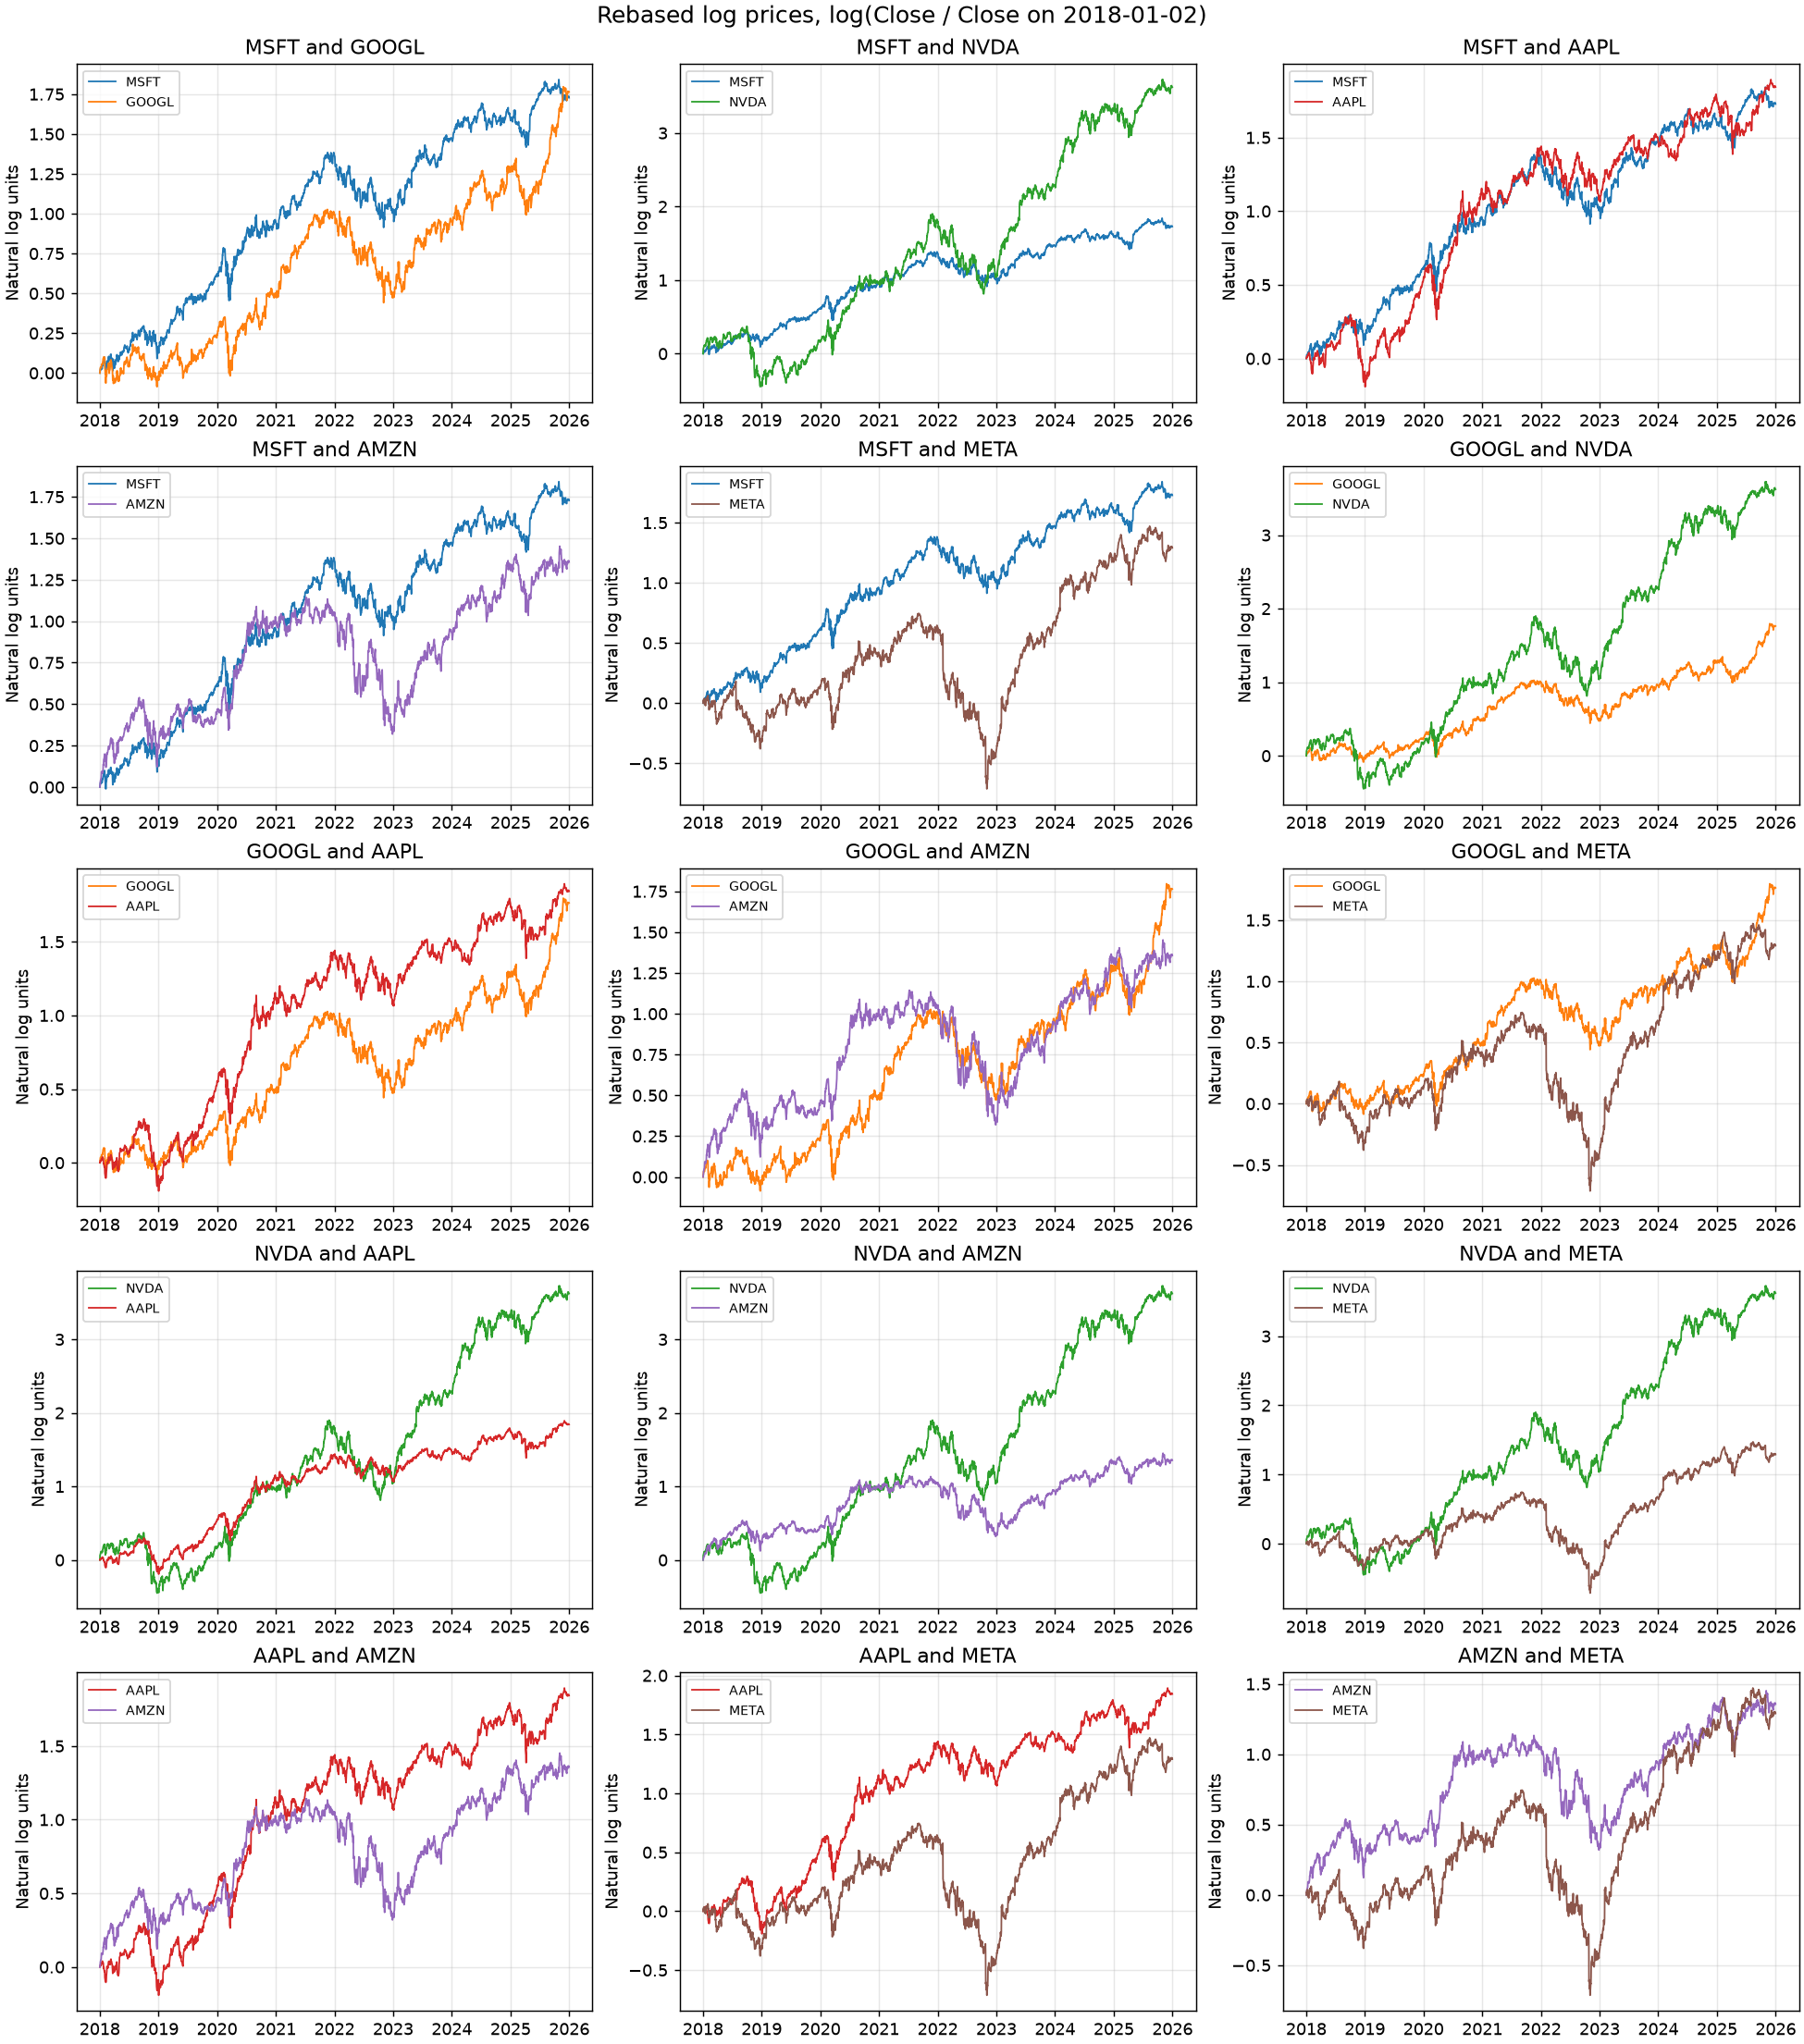

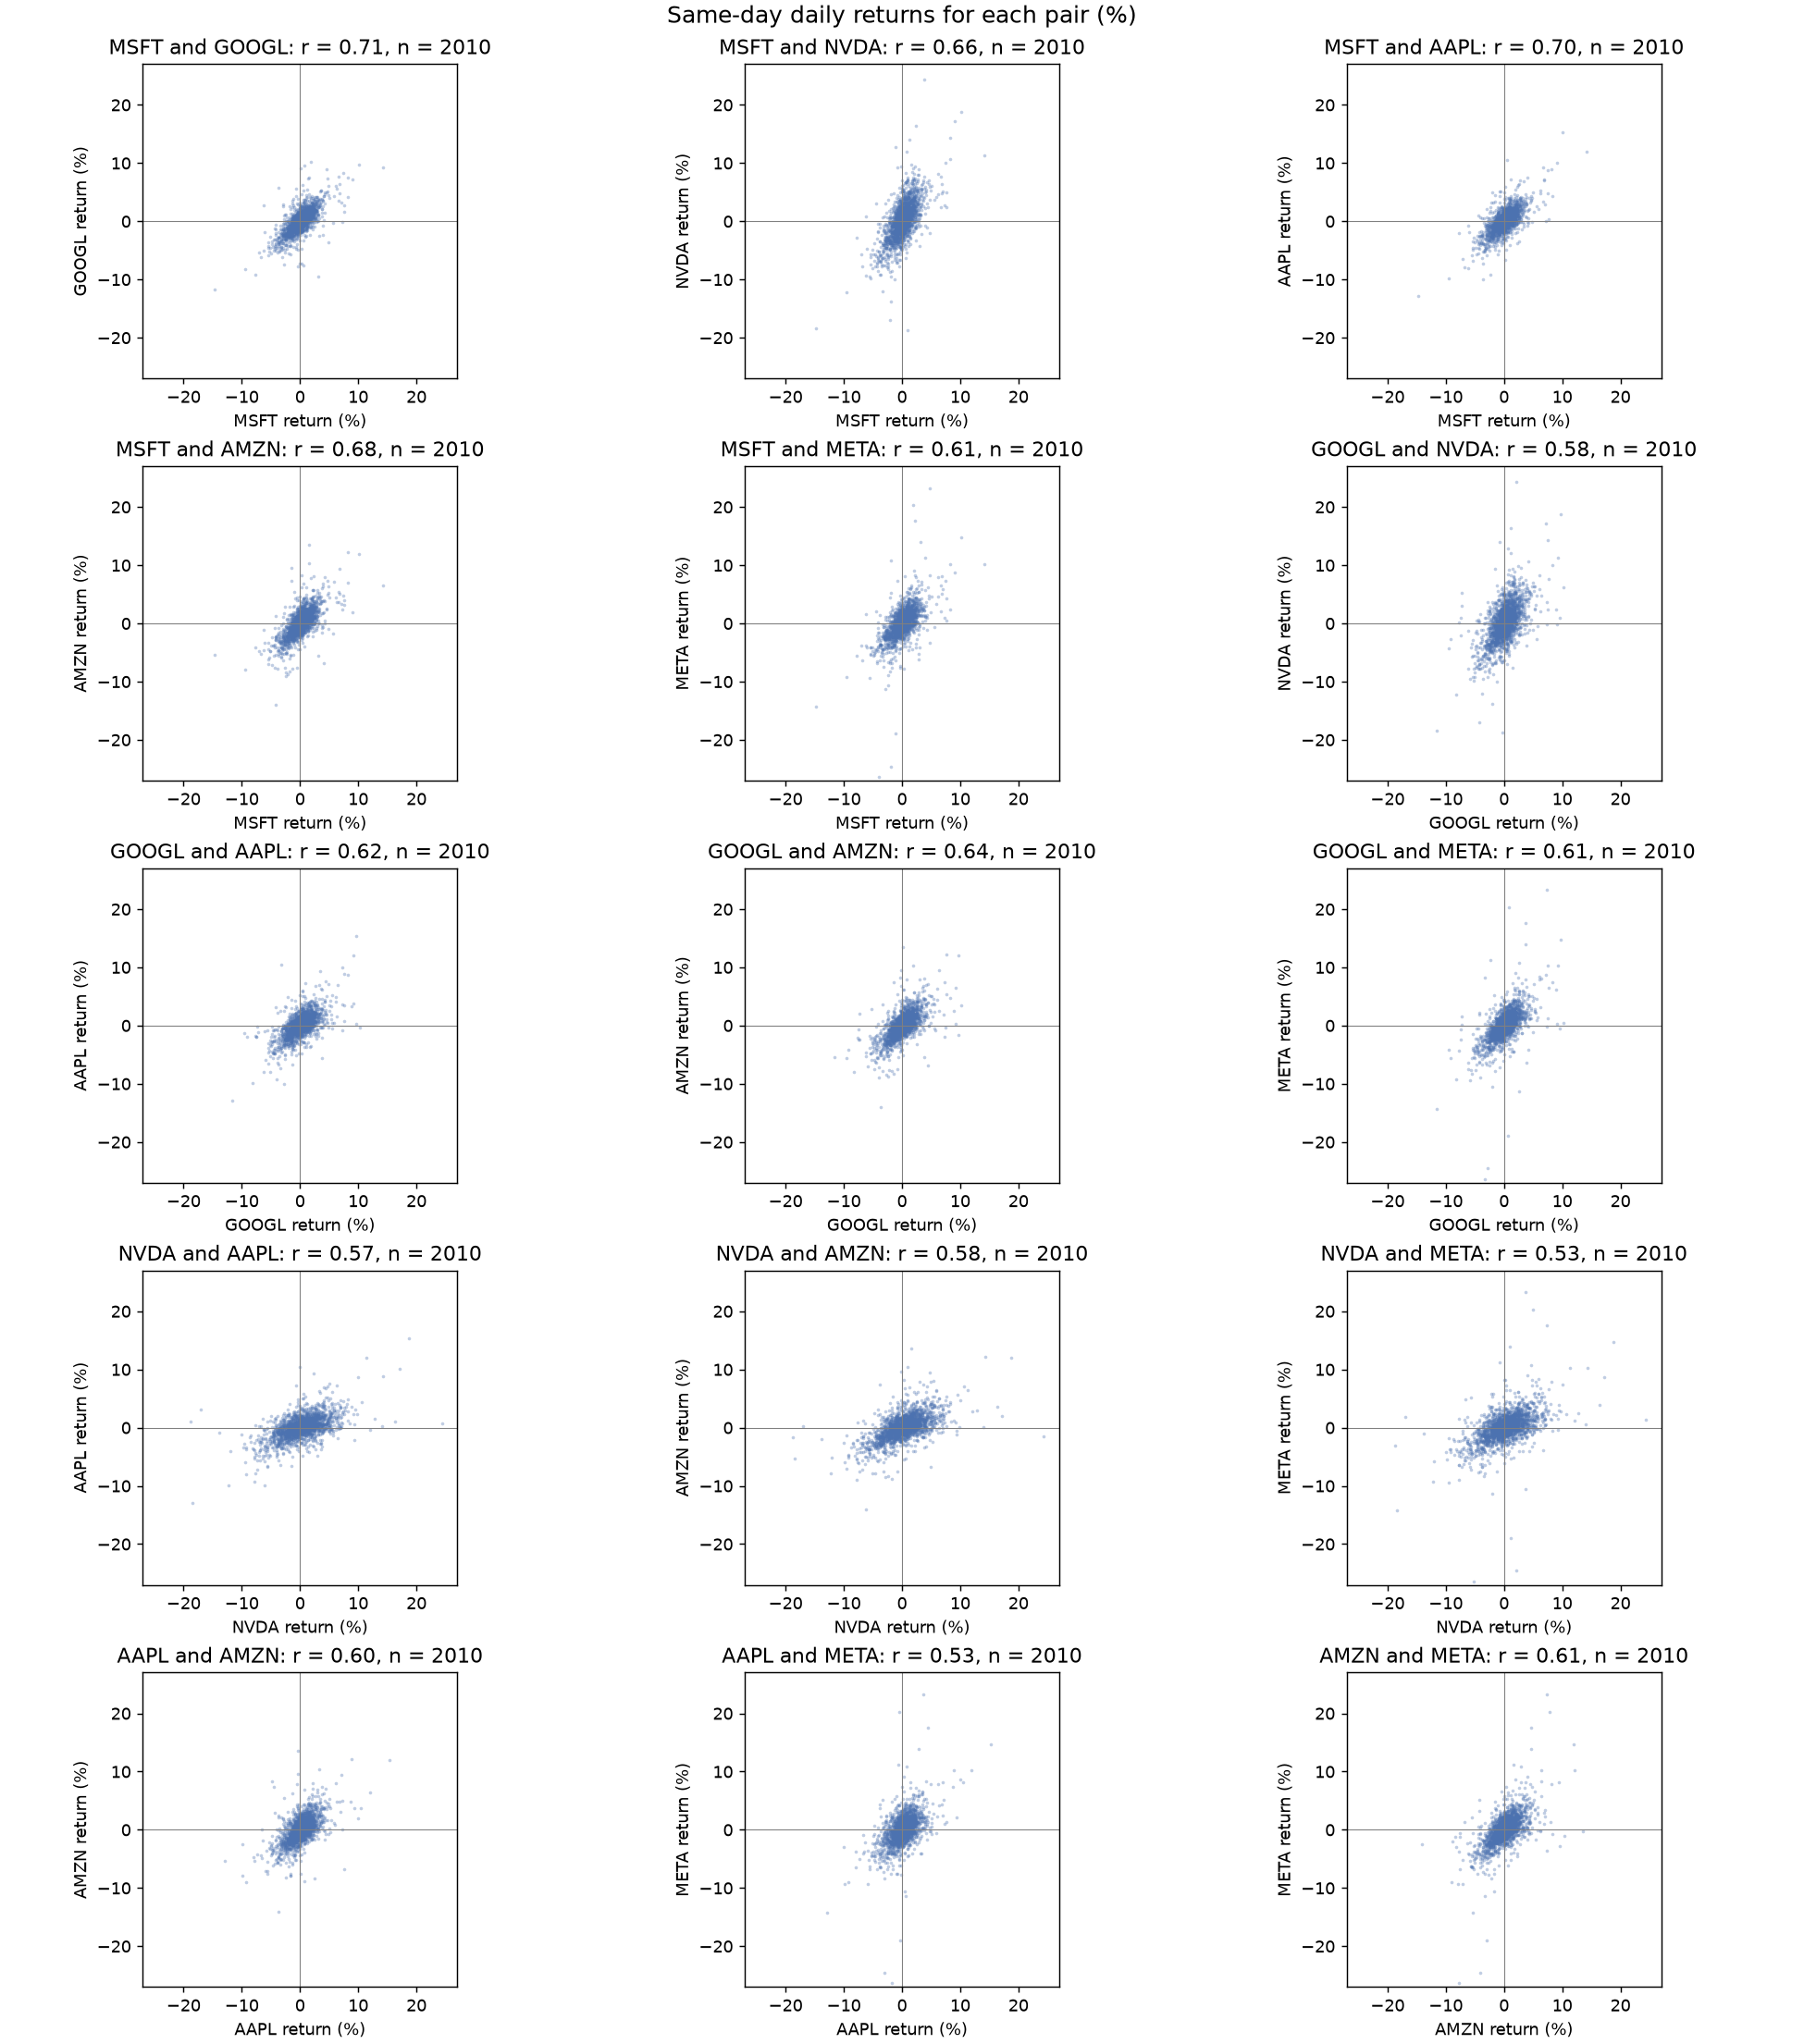

In [5]:
pairs = table('pair_correlations')
display(pairs[['pair', 'return_correlation', 'return_n', 'log_price_correlation', 'log_price_n']])
display(Image(FIGURES / 'return_correlation_heatmap.png'))
display(Image(FIGURES / 'pair_log_prices.png'))
display(Image(FIGURES / 'pair_return_scatter.png'))

Daily-return correlations range from 0.525 (NVDA_META) to 0.708 (MSFT_GOOGL). All 15 pairs have a positive linear association in same-day returns, whose strength changes over time. Log-price correlations are higher for every pair, between 0.728 (AAPL_META) and 0.977 (MSFT_AAPL), alongside the upward trends visible in the price panels. NVDA's log price correlates at 0.94 with MSFT's even though NVDA's Close rose about eight times as much in percentage terms. These panels compare log prices with equal weights. Phase 3 will estimate an intercept and hedge ratio before testing a residual spread, so separation of the unweighted lines alone cannot establish whether that fitted spread is stationary.

## Sensitivity to the S&P 500

Each regression is stock_return = alpha + beta * GSPC_return, on same-day percentage returns with an intercept. Beta is the fitted change in the stock's return for a one percentage point change in the S&P 500 return. This describes the historical association; it is not a causal effect, a CAPM estimate using excess returns, or a cointegration hedge ratio.

,alpha_pct,beta,r_squared,correlation,n
stock,,,,,
MSFT,0.038,1.177,0.661,0.813,2010
GOOGL,0.044,1.156,0.535,0.731,2010
NVDA,0.134,1.822,0.485,0.696,2010
AAPL,0.045,1.215,0.598,0.773,2010
AMZN,0.027,1.178,0.450,0.671,2010
META,0.028,1.318,0.388,0.623,2010


period,2018,2019,2020,2021,2022,2023,2024,2025
stock,,,,,,,,
AAPL,1.25,1.56,1.12,1.31,1.31,1.11,0.96,1.30
AMZN,1.62,1.33,0.68,1.05,1.64,1.53,1.54,1.38
GOOGL,1.36,1.28,0.95,1.29,1.34,1.38,1.24,1.08
META,1.27,1.27,0.99,1.29,1.74,1.77,1.55,1.43
MSFT,1.45,1.30,1.12,1.15,1.28,1.18,1.18,0.91
NVDA,1.91,2.28,1.33,2.01,2.21,2.04,2.67,1.96


period,2018,2019,2020,2021,2022,2023,2024,2025
stock,,,,,,,,
AAPL,0.55,0.55,0.69,0.47,0.78,0.52,0.29,0.56
AMZN,0.59,0.52,0.37,0.32,0.63,0.37,0.48,0.57
GOOGL,0.68,0.45,0.73,0.48,0.71,0.36,0.31,0.39
META,0.32,0.32,0.55,0.33,0.43,0.34,0.29,0.50
MSFT,0.76,0.66,0.77,0.52,0.77,0.38,0.56,0.50
NVDA,0.44,0.49,0.63,0.34,0.71,0.31,0.41,0.55


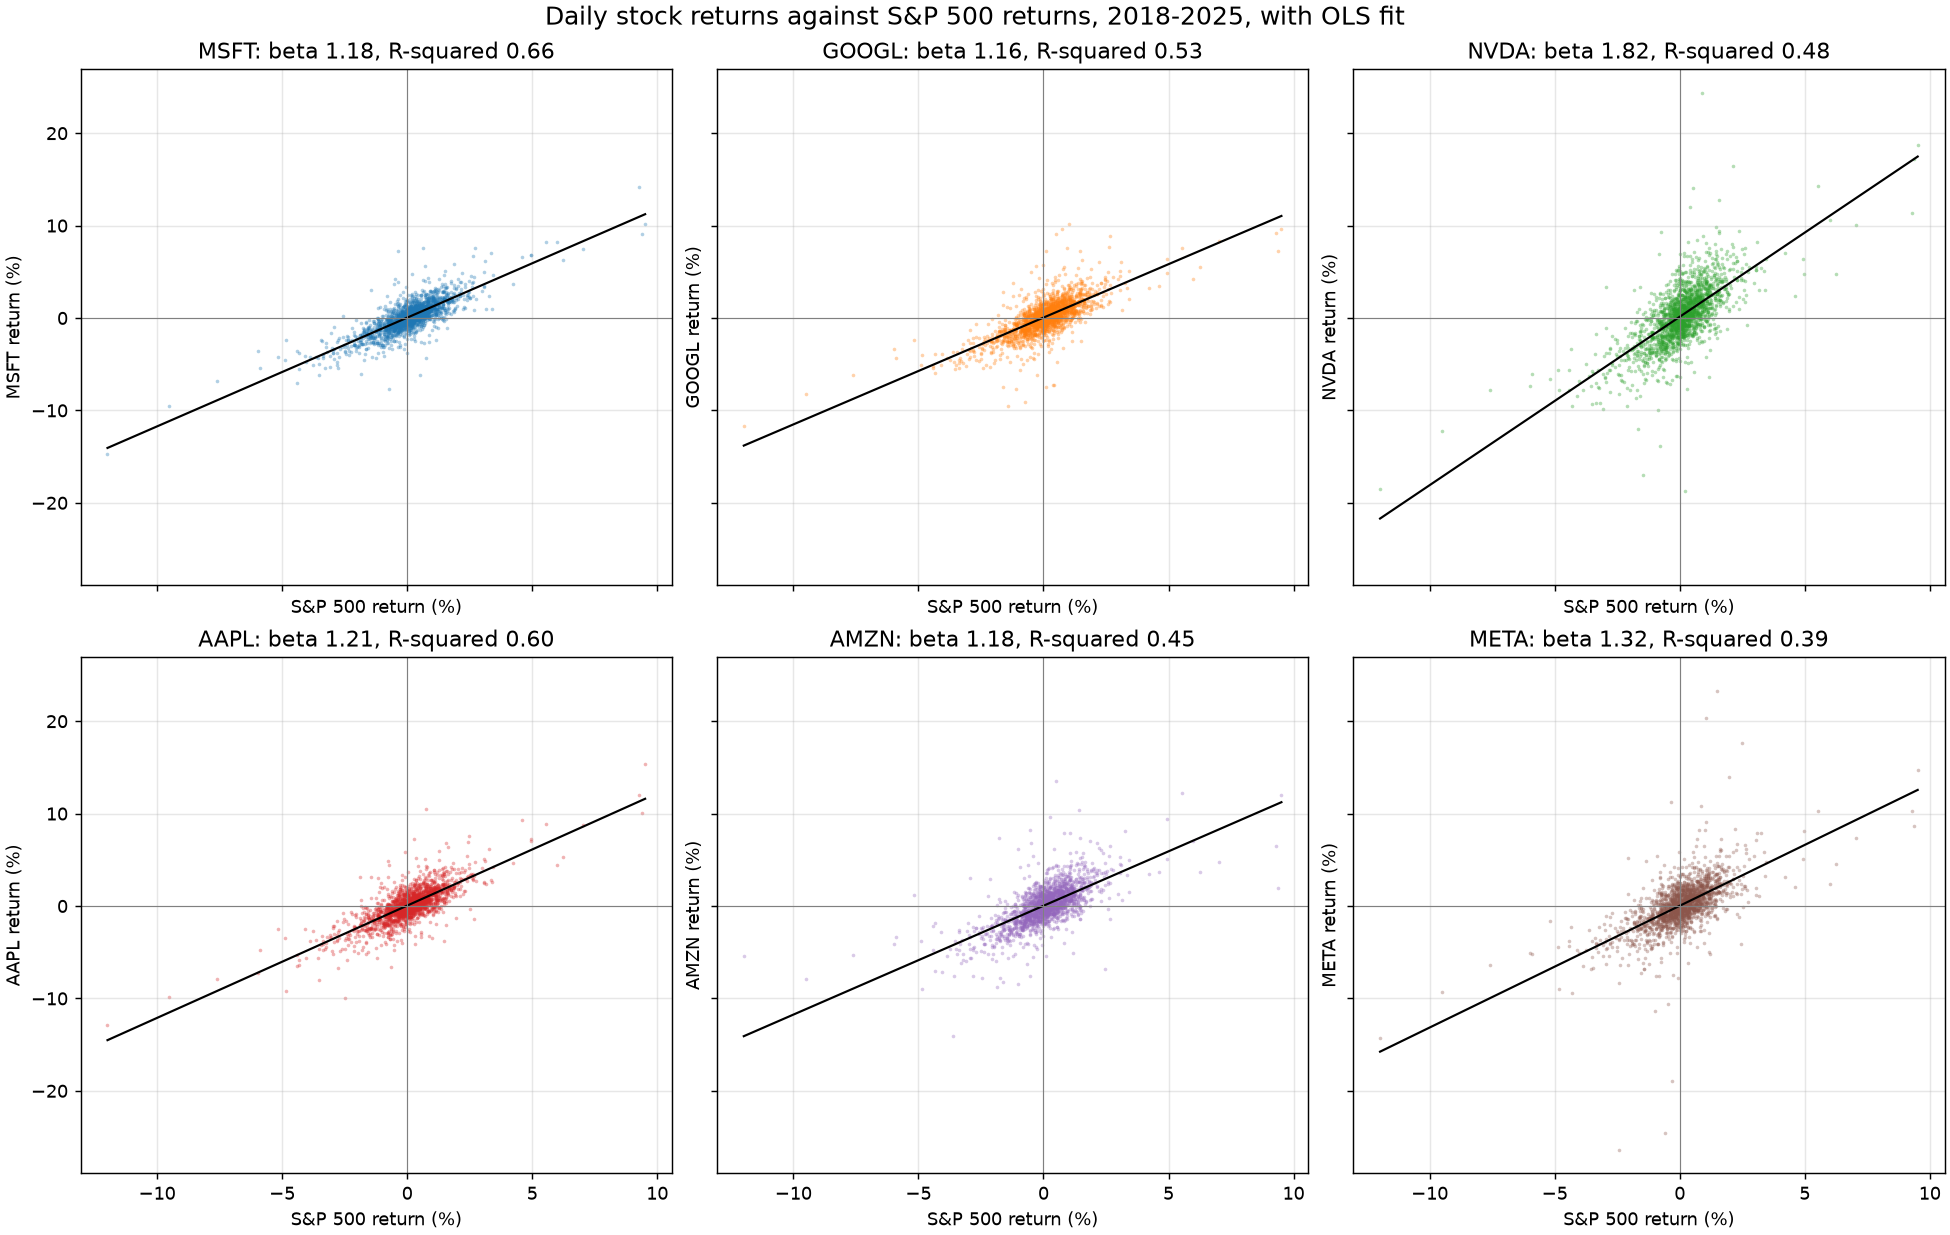

In [6]:
benchmark = table('benchmark_sensitivity')
display(benchmark[benchmark['period'].eq('2018-2025')].set_index('stock')[['alpha_pct', 'beta', 'r_squared', 'correlation', 'n']])
years = benchmark[benchmark['period'].ne('2018-2025')]
display(years.pivot(index='stock', columns='period', values='beta').round(2))
display(years.pivot(index='stock', columns='period', values='r_squared').round(2))
display(Image(FIGURES / 'benchmark_scatter.png'))

All six betas are above 1 over the whole period, from 1.16 for GOOGL to 1.82 for NVDA. The fitted regression explains the most daily variation for MSFT (R-squared 0.66) and the least for META (0.39). About 61% of META's daily-return variation remains unexplained by this single-benchmark regression; the analysis does not identify its causes. Year by year, NVDA's beta ranged from 1.33 in 2020 to 2.67 in 2024. 2020 gave the lowest annual beta for AMZN, GOOGL, META, and NVDA. For GOOGL and META it was also the year with the highest R-squared, so those stocks followed the index more closely in that year's fitted regressions while moving less per percentage point of index return.

## Stability over time

Annual correlations use each calendar year's returns. The rolling view uses a fixed trailing window of 60 paired returns that includes the labelled day, so the first complete window ends on 2018-03-29 and the 59 dates before it are kept as incomplete. The window length was fixed before any result was seen and was not varied.

year,2018,2019,2020,2021,2022,2023,2024,2025
pair,,,,,,,,
MSFT_GOOGL,0.82,0.63,0.86,0.72,0.85,0.51,0.57,0.42
MSFT_NVDA,0.63,0.56,0.84,0.59,0.79,0.54,0.46,0.64
MSFT_AAPL,0.70,0.62,0.84,0.68,0.82,0.54,0.47,0.49
MSFT_AMZN,0.77,0.72,0.74,0.58,0.74,0.57,0.69,0.59
MSFT_META,0.55,0.52,0.76,0.51,0.63,0.53,0.57,0.65
GOOGL_NVDA,0.65,0.46,0.76,0.50,0.77,0.40,0.32,0.48
GOOGL_AAPL,0.67,0.56,0.75,0.55,0.80,0.51,0.36,0.50
GOOGL_AMZN,0.74,0.62,0.68,0.59,0.72,0.60,0.54,0.54
GOOGL_META,0.63,0.57,0.80,0.58,0.68,0.61,0.39,0.44


,windows
status,
ok,29265
incomplete_window,885


,min,mean,max
pair,,,
MSFT_GOOGL,0.05,0.65,0.94
MSFT_NVDA,0.28,0.61,0.92
MSFT_AAPL,-0.03,0.61,0.95
MSFT_AMZN,0.16,0.66,0.88
MSFT_META,0.03,0.59,0.92
GOOGL_NVDA,0.08,0.52,0.90
GOOGL_AAPL,0.10,0.56,0.93
GOOGL_AMZN,0.07,0.61,0.91
GOOGL_META,0.06,0.58,0.94


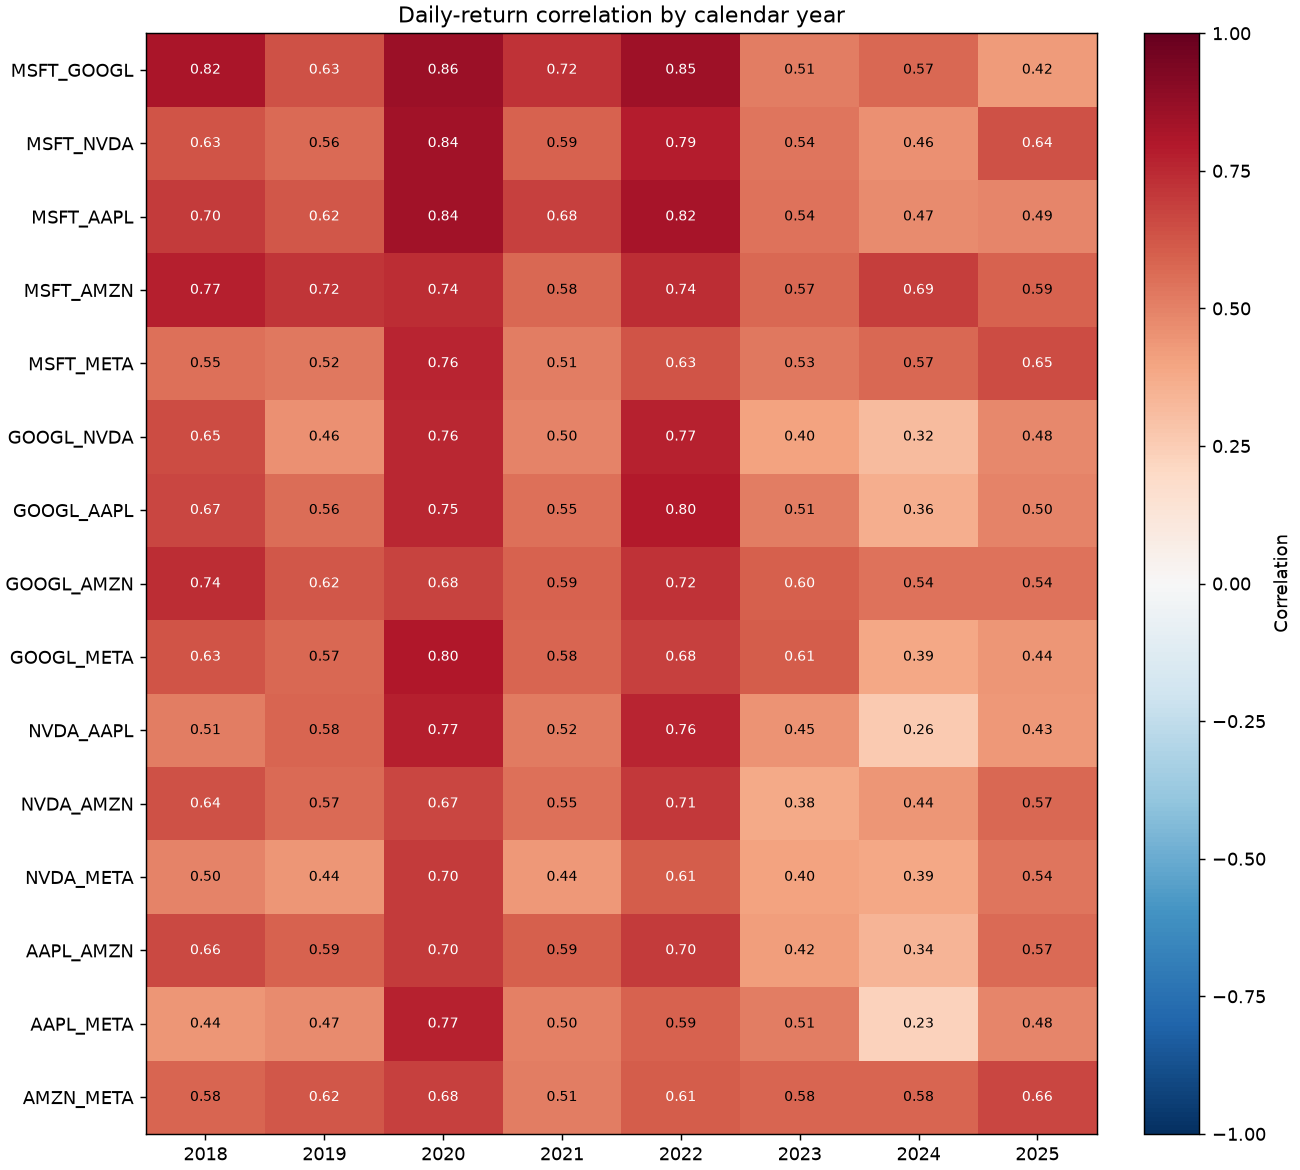

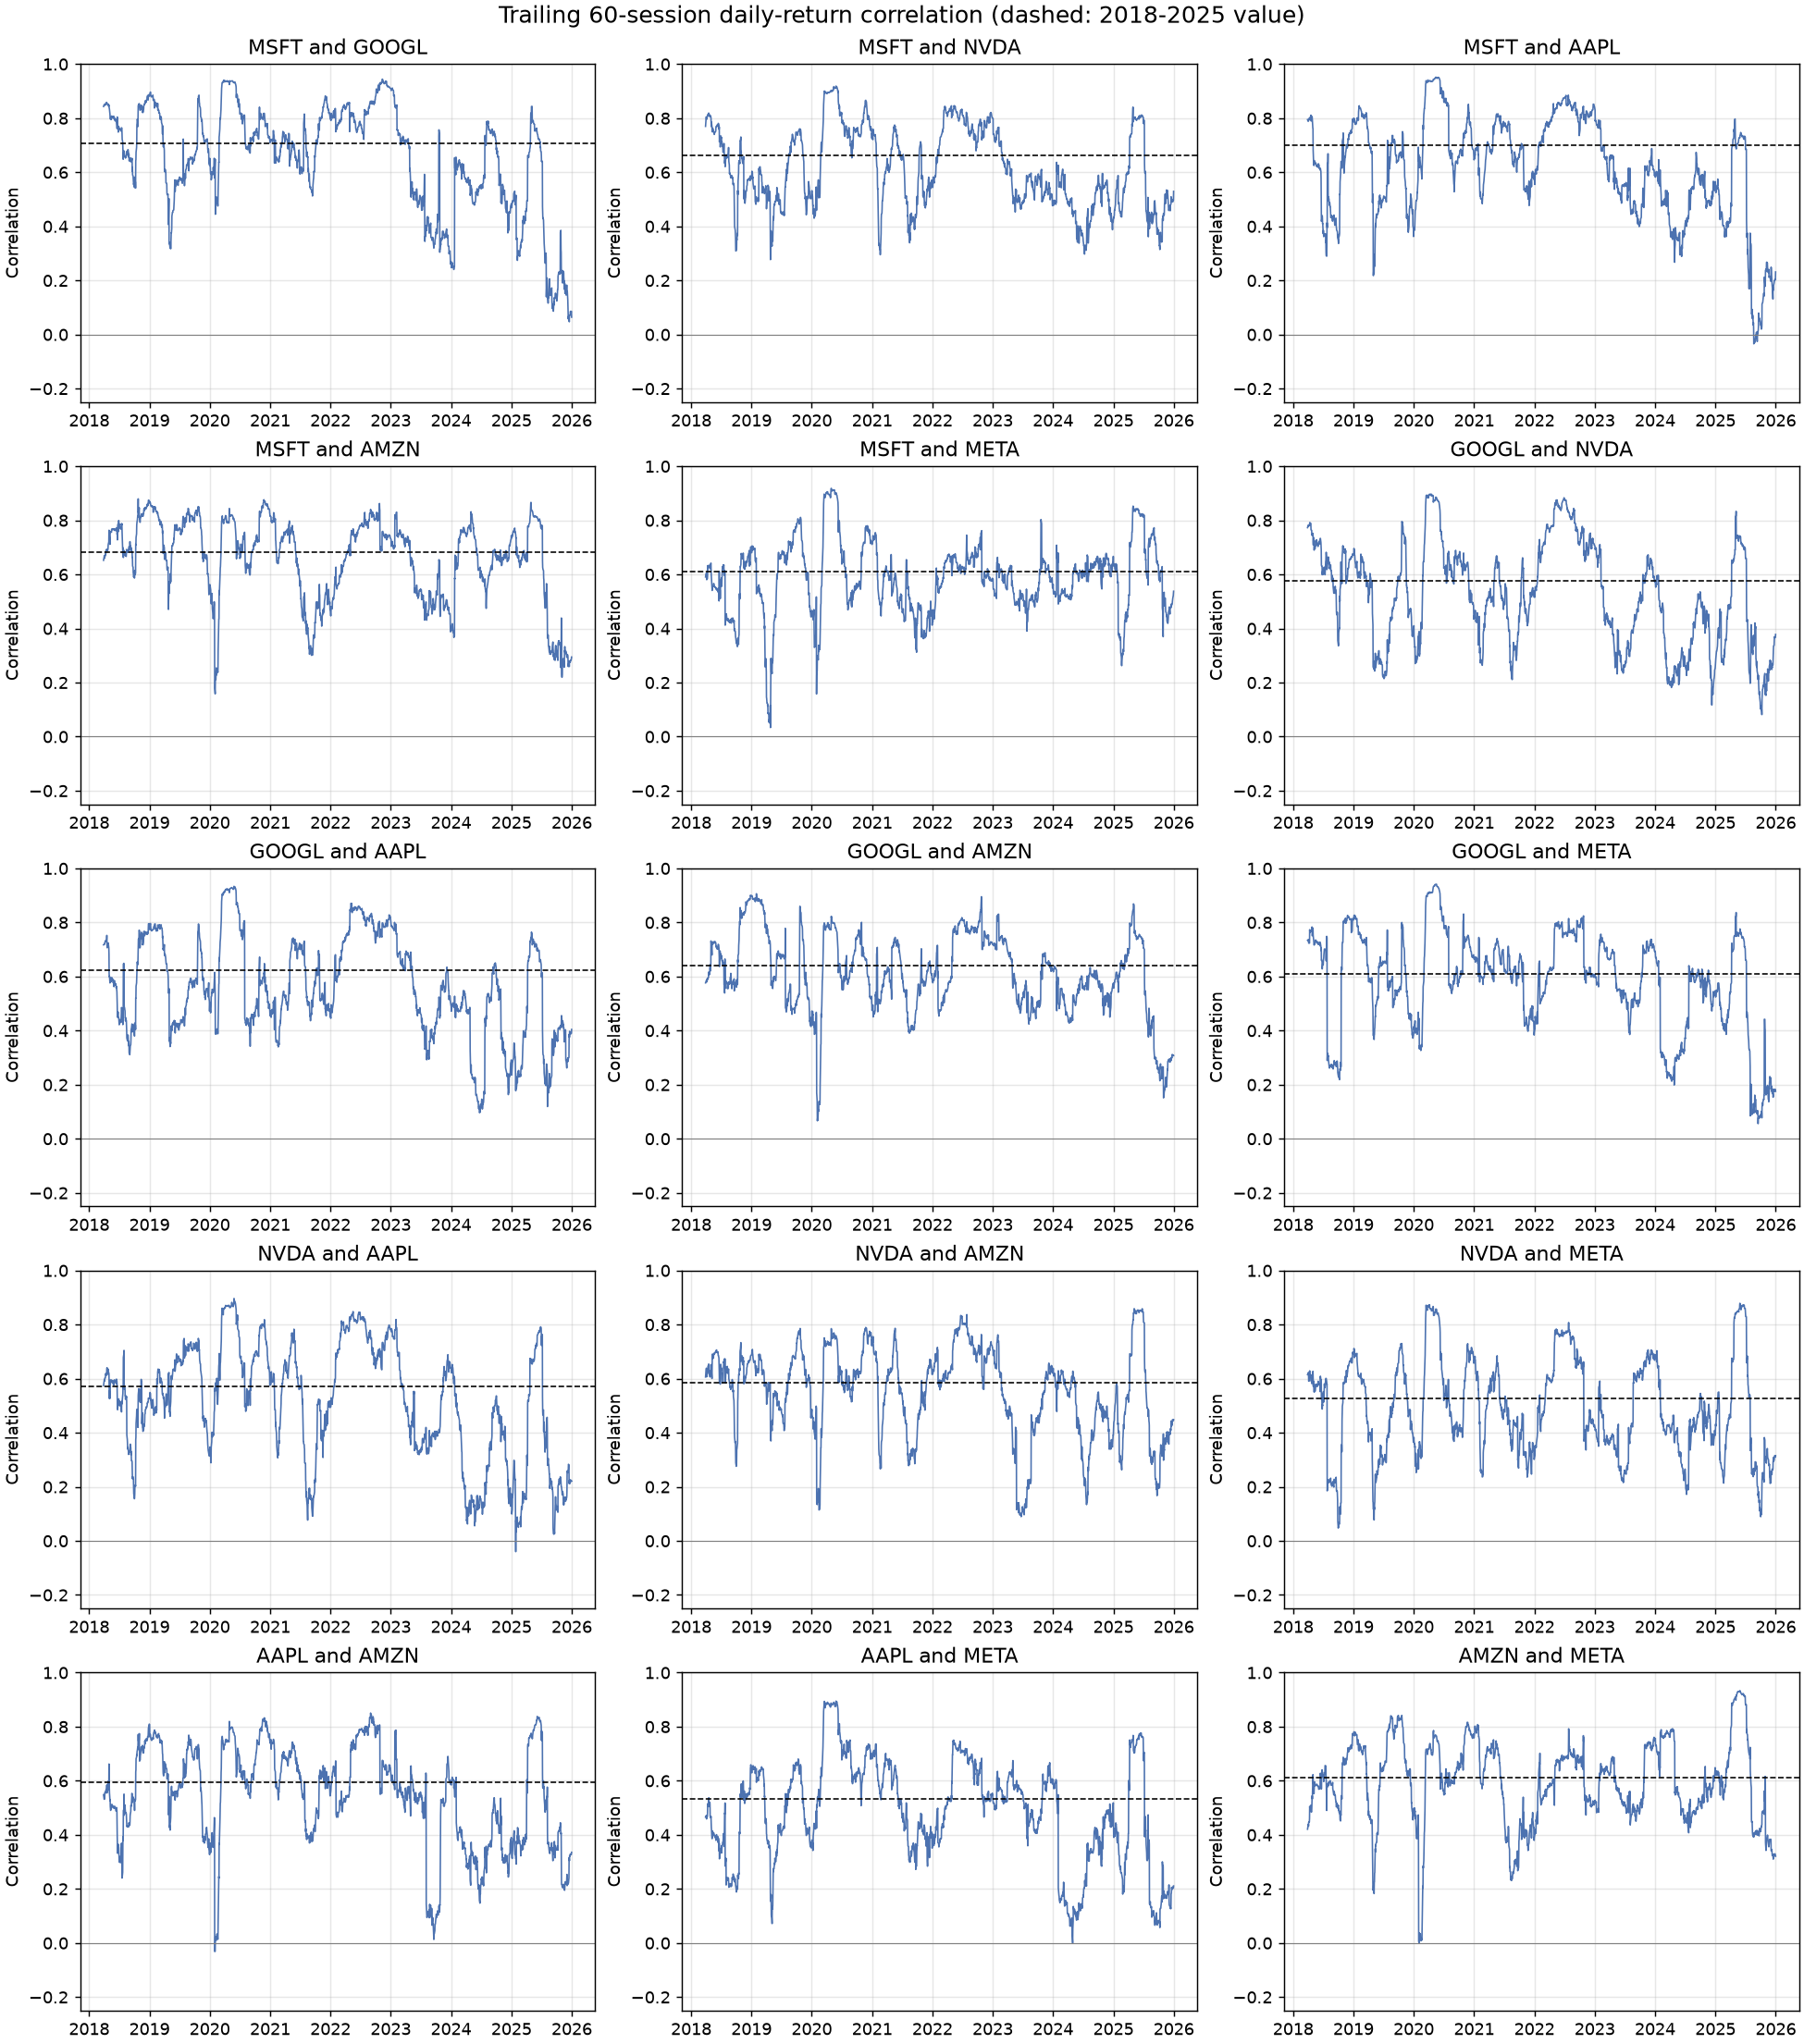

In [7]:
pair_years = table('pair_annual_correlations')
display(pair_years.pivot(index='pair', columns='year', values='correlation').loc[pairs['pair']].round(2))
rolling = table('rolling_correlations')
display(rolling['status'].value_counts().rename('windows').to_frame())
defined = rolling[rolling['status'].eq('ok')]
display(defined.groupby('pair', sort=False)['correlation'].agg(['min', 'mean', 'max']).round(2))
display(Image(FIGURES / 'pair_annual_correlation_heatmap.png'))
display(Image(FIGURES / 'rolling_correlations.png'))

The relationships are far from constant. Annual correlations were highest in 2020 (0.67 to 0.86 across pairs) and 2022 (0.59 to 0.85) and lowest in 2024 (0.23 to 0.69). Every pair had at least one 60-session window below 0.30, and 16 windows across three pairs (MSFT_AAPL, AAPL_AMZN, NVDA_AAPL) fell slightly below zero, the lowest -0.04 for NVDA_AAPL ending 2025-01-27. The highest was 0.95 for MSFT_AAPL in May 2020. At the end of 2025 MSFT_GOOGL, the most correlated pair over the full period, was at 0.06. A whole-period correlation hides these swings, which matters for Phase 3: a relationship estimated on eight years may not describe the final year.

## VIX context

The VIX groups split the 2,010 return dates at the one-third and two-thirds quantiles of Cboe's VIX close (linear interpolation). A value equal to a boundary goes to the lower group. The boundaries describe this sample only; they are not trading thresholds.

Boundaries: [15.93, 20.743333333333332] estimated on 2010 dates 2018-01-03 to 2025-12-31


vix_group,low,medium,high
instrument,,,
AAPL,1.219,1.575,2.692
AMZN,1.347,1.942,2.903
GOOGL,1.452,1.775,2.472
GSPC,0.542,0.856,1.871
META,1.906,2.313,3.370
MSFT,1.105,1.414,2.512
NVDA,2.281,3.233,3.937


vix_group,low,medium,high
instrument,,,
AAPL,0.919,1.169,1.958
AMZN,1.034,1.419,2.178
GOOGL,1.012,1.311,1.851
GSPC,0.447,0.658,1.322
META,1.242,1.566,2.337
MSFT,0.859,1.068,1.821
NVDA,1.713,2.328,2.998


vix_group,low,medium,high
pair,,,
MSFT_GOOGL,0.422,0.584,0.840
MSFT_NVDA,0.391,0.579,0.782
MSFT_AAPL,0.376,0.573,0.803
MSFT_AMZN,0.543,0.573,0.752
MSFT_META,0.392,0.565,0.682
GOOGL_NVDA,0.264,0.477,0.737
GOOGL_AAPL,0.325,0.524,0.745
GOOGL_AMZN,0.473,0.575,0.719
GOOGL_META,0.337,0.557,0.724


year,2018,2019,2020,2021,2022,2023,2024,2025
vix_group,,,,,,,,
low,134,162,28,15,0,106,167,60
medium,69,81,9,155,32,118,69,135
high,47,9,216,82,219,26,16,55


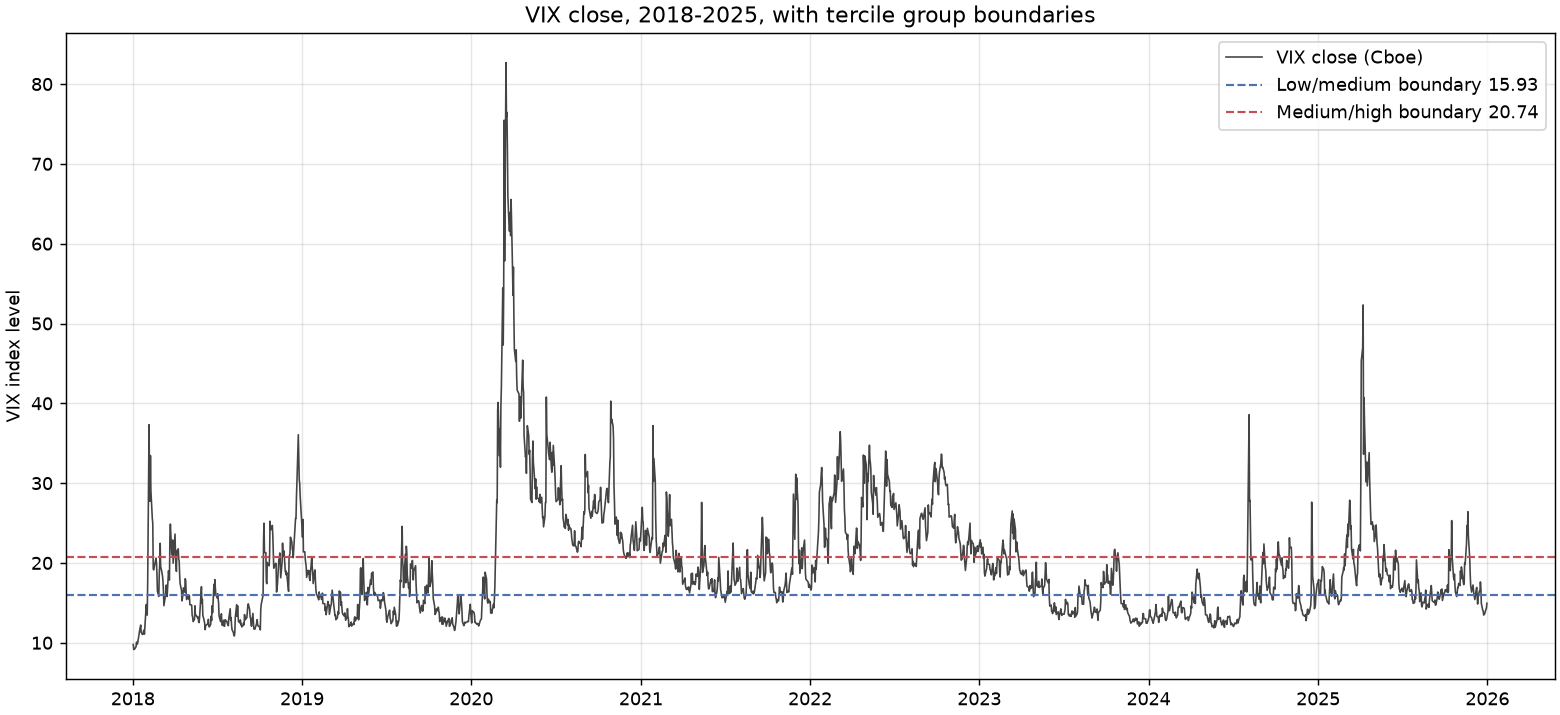

In [8]:
groups = metadata['vix_groups']
print('Boundaries:', groups['boundaries'], 'estimated on', groups['estimation_n'], 'dates',
      groups['estimation_first_date'], 'to', groups['estimation_last_date'])
vix_stock = table('vix_group_stock_summary')
display(vix_stock.pivot(index='instrument', columns='vix_group', values='std_pct')[groups['labels']])
display(vix_stock.pivot(index='instrument', columns='vix_group', values='mean_abs_pct')[groups['labels']])
vix_pairs = table('vix_group_pair_correlations')
display(vix_pairs.pivot(index='pair', columns='vix_group', values='correlation').loc[pairs['pair'], groups['labels']])
display(table('vix_group_year_counts').pivot(index='vix_group', columns='year', values='n').loc[groups['labels']])
display(Image(FIGURES / 'vix_timeline.png'))

The boundaries are 15.93 and 20.74, giving 672 low, 668 medium, and 670 high dates. Daily volatility rises from the low to the high group for all seven series: by a factor of 3.45 for the S&P 500 and between 1.70 (GOOGL) and 2.27 (MSFT) for the stocks. All 15 pair correlations also rise with VIX, from 0.20-0.54 in the low group to 0.65-0.84 in the high group.

The year counts limit how far this can be read. 435 of the 670 high-VIX dates fall in 2020 and 2022, and 2022 has no low-VIX dates at all, so the comparison partly contrasts those two years with calm years such as 2019 and 2024. It shows that higher VIX coincided with more volatile and more correlated returns in this sample, not that VIX causes either. VIX is not added to the strategy or the LSTM by this analysis.

## Saved outputs

Tables are in `outputs/metrics/eda/` and figures in `outputs/figures/eda/`. `run_metadata.json` records the input and settings hashes, the VIX boundaries at full precision, library versions, every check, and the hash of each table.

In [9]:
display(pd.DataFrame(metadata['outputs'].items(), columns=['table', 'sha256']))
print(json.dumps(metadata['versions'], indent=2))

,table,sha256
0,outputs/metrics/eda/stock_summary.csv,be1d9140c32593a2466fb177c2554ae9e79155e2c3bb2c...
1,outputs/metrics/eda/stock_annual_summary.csv,8b05f93d69b87d5d1443121fb511784b35ea5c4980b33e...
2,outputs/metrics/eda/pair_correlations.csv,7b4a321d83943e27049df819c43776939d813e18447ff7...
3,outputs/metrics/eda/return_correlation_matrix.csv,bf0cb5c88e92e6d207ec592315c4c9514f131d8c8784ee...
4,outputs/metrics/eda/benchmark_sensitivity.csv,82e1fa76ed41ba2a60d2ea4cf8cab63128592f224ccf3f...
5,outputs/metrics/eda/pair_annual_correlations.csv,a21eac7d9fe32be07ee2572ce7d82fded73e65abefbade...
6,outputs/metrics/eda/rolling_correlations.csv,864ac693f971d04538172dddfb60b25ba65ee3b5ec4359...
7,outputs/metrics/eda/vix_group_stock_summary.csv,4486192564add544e5d9d53453cf881ffb7ea5b59ccd80...
8,outputs/metrics/eda/vix_group_pair_correlation...,48699b9ed02713dcd9c23838d052fff57b1270dd7a4ee3...
9,outputs/metrics/eda/vix_group_year_counts.csv,ca4ae7d40db5087a946c3627263941d3719f0f9e8667e7...


{
  "python": "3.12.13",
  "pandas": "3.0.6",
  "numpy": "2.5.4",
  "statsmodels": "0.15.0",
  "matplotlib": "3.11.2"
}
